# Compute accuracy plot for sMNIST

In [66]:
import matplotlib.pyplot as plt
import numpy as np
import pickle as p
import pandas as pd
import warnings

warnings.simplefilter(action="ignore", category=UserWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

# Use TeX.
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
    }
)

# Configure font sizes.
SMALL_SIZE = 7 + 1
MEDIUM_SIZE = 8 + 1
BIGGER_SIZE = 10 + 1
plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=MEDIUM_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [67]:
with open("./smnist_seq_imzx6zi3.pkl", "rb") as f:
    seq = p.load(f)

In [68]:
with open("./smnist_977si1an.pkl", "rb") as f:
    parr = p.load(f)

In [69]:
parr.columns

Index(['_timestamp', 'val_loss', '_runtime', 'train_time',
       'trainer/global_step', 'val_accuracy', 'test_loss', '_step',
       'test_accuracy', 'run_id', 'model_cfg.learn_diags', 'model_cfg',
       'trainer_cfg', 'model_cfg.clip', 'Comment', 'model_cfg.method',
       'model_cfg.parallel', 'data_cfg', 'model_cfg.num_iters',
       'optimizer_cfg', 'logger_cfg', 'seed'],
      dtype='object')

In [70]:
parr_series = parr[~parr["model_cfg.clip"]][parr["model_cfg.method"]=='gru'][~parr["test_accuracy"].isna()][
    ["seed", "model_cfg.num_iters", "test_accuracy"]
].groupby(["model_cfg.num_iters"]).mean().unstack()['test_accuracy']
parr_series_std = (
    parr[~parr["model_cfg.clip"]][parr["model_cfg.method"] == "gru"][
        ~parr["test_accuracy"].isna()
    ][["seed", "model_cfg.num_iters", "test_accuracy"]]
    .groupby(["model_cfg.num_iters"])
    .std()
    .unstack()["test_accuracy"]
)
num_iters = parr_series.index.tolist()
test_accuracy = [100 * t for t in parr_series.values.tolist()]
test_accuracy_std = parr_series_std.values.tolist()

In [71]:
seq_test_acc = (
    seq[~seq["test_accuracy"].isna()][["test_accuracy"]].mean().item()
)  
seq_test_std = seq[~seq["test_accuracy"].isna()][["test_accuracy"]].std().item()
print(f"the accuracy of sequential is {round(100 * seq_test_acc, 2)}")
print(f"the standard deviation of sequential over 3 seeds is {round(100 * seq_test_std, 2)}")

the accuracy of sequential is 98.51
the standard deviation of sequential over 3 seeds is 0.24


In [72]:
test_accuracy

[63.96999955177307,
 89.21666344006857,
 97.19333052635193,
 97.18333085378012,
 96.47999604543051,
 98.42999974886575]

In [73]:
test_accuracy_std

[0.0074806384379223914,
 0.026958533597578903,
 0.003914488130338419,
 0.01137996799484461,
 0.023586439294625134,
 0.0001731994095344338]

<>:9: SyntaxWarning: invalid escape sequence '\%'
<>:9: SyntaxWarning: invalid escape sequence '\%'
/var/folders/tf/ybkfqmld4yb8_yn2xr11sl8m0000gn/T/ipykernel_39889/3396441856.py:9: SyntaxWarning: invalid escape sequence '\%'
  axs.set_ylabel("Test accuracy (\%)")


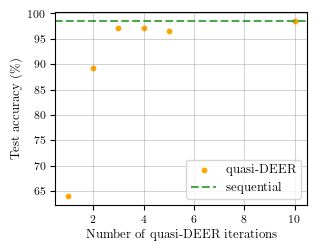

In [90]:
# Create figure and axes
fig, axs = plt.subplots(figsize=(3.25, 2.5))

# Scatter plot
axs.scatter(num_iters, test_accuracy, s=10, color="orange", label="quasi-DEER")

# Labels
axs.set_xlabel("Number of quasi-DEER iterations")
axs.set_ylabel("Test accuracy (\%)")

# Horizontal line
axs.set_xlim(0.5, 10.5)  # Adjust as needed to add some padding
axs.hlines(
    100 * seq_test_acc, xmin=0.5, xmax=10.5, linestyle="--", alpha=0.7, color='green', label="sequential"
)

# Add grid
axs.grid(color="gray", linewidth=0.5, alpha=0.5)
axs.legend(loc="lower right")  # Adjust location as needed
plt.savefig("smnist_compute_accuracy.pdf", bbox_inches="tight")